# Freight Rate Data Analysis

Exploration behind `train.py`: what the data looks like, which data-quality issues exist,
and the decision taken for each one. Every number in `report.md` comes from a cell here.

Sections:
1. Load and overview
2. Data-quality issues (missing values, negative weights, price outliers, 70-mile trips, unseen cities)
3. Price drivers (distance, equipment, market index, day of week)
4. December chart inputs
5. Summary of decisions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from train import haversine_mi, DATA_DIR

pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 3.6)

train = pd.read_csv(DATA_DIR / "train_test.csv", parse_dates=["date"])
val = pd.read_csv(DATA_DIR / "validation.csv", parse_dates=["date"])
dec = pd.read_csv(DATA_DIR / "december_chart_inputs.csv")

for name, df in [("train_test", train), ("validation", val)]:
    print(f"{name:11s} rows={len(df):,}  dates {df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}")
train.head()

train_test  rows=48,000  dates 2025-01-01 to 2025-10-31
validation  rows=12,000  dates 2025-11-01 to 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 1. Overview

Training covers **Jan–Oct 2025**, validation covers **Nov–Dec 2025**. This is a forecasting
problem, so a random train/test split would leak future information. All validation in
`train.py` is time-based for this reason.

In [2]:
train.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.399999,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


## 2. Data-quality issues

### 2.1 Missing values and duplicates

In [3]:
missing = pd.DataFrame({"train_test": train.isna().sum(), "validation": val.isna().sum()})
print(missing[missing.sum(axis=1) > 0])
print("\nduplicate load_id:", train.load_id.duplicated().sum(),
      "| duplicate rows (ignoring load_id):", train.drop(columns="load_id").duplicated().sum())

              train_test  validation
market_index         374       249.0
weight               300       165.0

duplicate load_id: 0 | duplicate rows (ignoring load_id): 0


Only `weight` and `market_index` have gaps (under 1% of rows), and there are no duplicates.
**Decision:** leave the gaps as NaN. `HistGradientBoostingRegressor` handles missing values
natively, which is safer than inventing values.

### 2.2 Negative weights

negative weights: 292 train, 145 validation
negative range: -47,500 to -5,000
positive range: 5,000 to 47,500


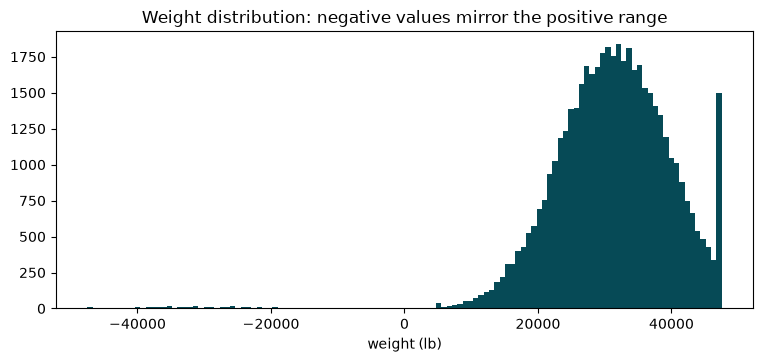

In [4]:
neg = train[train.weight < 0]
print(f"negative weights: {len(neg)} train, {(val.weight < 0).sum()} validation")
print(f"negative range: {neg.weight.min():,.0f} to {neg.weight.max():,.0f}")
print(f"positive range: {train.weight[train.weight > 0].min():,.0f} to {train.weight.max():,.0f}")

fig, ax = plt.subplots()
ax.hist(train.weight.dropna(), bins=120, color="#064A56")
ax.set(title="Weight distribution: negative values mirror the positive range", xlabel="weight (lb)")
plt.show()

The negative values have the same magnitudes as normal loads (5,000 to 47,500 lb), so they
are sign flips, not a separate population. **Decision:** `abs()` in `clean()`.

### 2.3 Price outliers (rate per mile)

count    48000.00
mean         2.22
std          0.58
min          0.33
0.1%         0.44
1%           1.67
5%           1.81
50%          2.15
95%          2.74
99%          3.18
99.9%       10.07
max         14.13

outside $1-$6 per mile: 599 rows (1.2%)


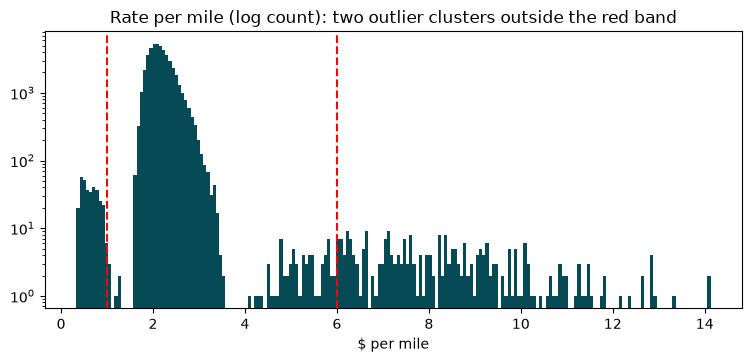

In [5]:
rpm = train.posted_rate / train.distance
print(rpm.describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).round(2).to_string())

outlier = (rpm < 1.0) | (rpm > 6.0)
print(f"\noutside $1-$6 per mile: {outlier.sum()} rows ({outlier.mean():.1%})")

fig, ax = plt.subplots()
ax.hist(rpm, bins=200, color="#064A56", log=True)
ax.axvline(1.0, color="red", ls="--"); ax.axvline(6.0, color="red", ls="--")
ax.set(title="Rate per mile (log count): two outlier clusters outside the red band", xlabel="$ per mile")
plt.show()

Normal loads sit around $1.70–$3.20 per mile. There are two small clusters of impossible prices,
one around $0.60–$0.90 and one around $8–$14, which look like unit or entry errors.
**Decision:** drop rows outside $1–$6 per mile from **training only** (`RPM_LO`, `RPM_HI` in
`train.py`). Prediction rows are never dropped, because every load needs a prediction.

In [6]:
outliers = train[outlier].assign(rpm=rpm[outlier].round(2))
outliers[["pickup", "delivery", "distance", "equipment", "posted_rate", "rpm"]].sort_values("rpm").head(8)

,pickup,delivery,distance,equipment,posted_rate,rpm
14102,Buffalo,Bakersfield,2536.4,Dry Van,846.42,0.33
25798,Albany,Reno,2894.3,Dry Van,969.83,0.34
46173,Philadelphia,El Paso,2490.9,Dry Van,880.13,0.35
23043,Phoenix,Philadelphia,2983.4,Dry Van,1047.91,0.35
508,Las Vegas,Grand Rapids,1976.4,Flatbed,699.41,0.35
2511,Buffalo,San Antonio,1644.3,Flatbed,596.04,0.36
22464,Kansas City,Los Angeles,1909.1,Dry Van,709.46,0.37
22458,Salt Lake City,Mobile,1632.3,Dry Van,599.77,0.37


### 2.4 Trips longer than the straight-line distance (the 70-mile floor)

Road distance should be about 1.2 times the straight-line distance. A few rows are far above that.

In [7]:
straight = haversine_mi(train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon)
ratio = train.distance / straight
print(ratio.describe(percentiles=[.01, .5, .99]).round(2).to_string())

odd = train[ratio > 2].assign(straight=straight[ratio > 2].round(1))
odd["rpm_listed"] = (odd.posted_rate / odd.distance).round(2)
odd["rpm_if_straight"] = (odd.posted_rate / (odd.straight * 1.18)).round(2)
print(f"\nrows with road distance > 2x straight-line: {len(odd)}")
odd[["pickup", "delivery", "distance", "straight", "posted_rate", "rpm_listed", "rpm_if_straight"]]

count    48000.00
mean         1.19
std          0.14
min          1.06
1%           1.13
50%          1.18
99%          1.40
max          9.63

rows with road distance > 2x straight-line: 22


,pickup,delivery,distance,straight,posted_rate,rpm_listed,rpm_if_straight
1464,Lubbock,Austin,70.0,34.5,235.59,3.37,5.79
1914,Lubbock,Austin,70.0,34.5,224.72,3.21,5.52
4140,New Orleans,Shreveport,70.0,7.3,197.06,2.82,22.88
5091,New Orleans,Shreveport,70.0,7.3,210.14,3.00,24.40
6960,New Orleans,Shreveport,70.0,7.3,223.52,3.19,25.95
8589,Austin,Lubbock,70.0,34.5,210.73,3.01,5.18
9348,Shreveport,New Orleans,70.0,7.3,232.33,3.32,26.97
11311,Lubbock,Austin,70.0,34.5,240.46,3.44,5.91
11327,Austin,Lubbock,78.9,34.5,246.54,3.12,6.06
11949,Shreveport,New Orleans,70.0,7.3,213.59,3.05,24.80


Every one of these rows is a **nearby city pair listed at exactly 70 miles**. With the listed
distance, the price is about $3 per mile, which is normal for a short haul. If we "fixed" the
distance to the straight line, the price would become $5–$27 per mile, which is nonsense.
So 70 miles is a **minimum-distance floor**, not an error.
**Decision:** keep distances as given. The `detour_ratio` feature lets the model learn
that these short trips price differently.

### 2.5 Cities in validation that never appear in training

In [8]:
train_cities = set(train.pickup) | set(train.delivery)
val_cities = set(val.pickup) | set(val.delivery)
unseen = sorted(val_cities - train_cities)
affected = val.pickup.isin(unseen) | val.delivery.isin(unseen)
print(f"cities in training: {len(train_cities)} | unseen in validation: {len(unseen)}")
print(unseen)
print(f"validation loads touching an unseen city: {affected.sum():,} ({affected.mean():.1%})")

coords_per_city = train.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().max()
print("\nmax distinct coordinates per city:", coords_per_city.to_dict())

cities in training: 64 | unseen in validation: 8
['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation loads touching an unseen city: 1,447 (12.1%)

max distinct coordinates per city: {'pickup_lat': 1, 'pickup_lon': 1}


A model that learned city names would have nothing to go on for these loads. Each city always
has the same coordinates, so coordinates are a reliable stand-in.
**Decision:** use coordinates, not city names, as features, and test this with the
unseen-city check in `train.py` (8 cities hidden from training).

## 3. Price drivers

correlation with posted_rate:
distance        0.978
weight          0.035
market_index    0.036
quote_signal   -0.043
posted_rate     1.000


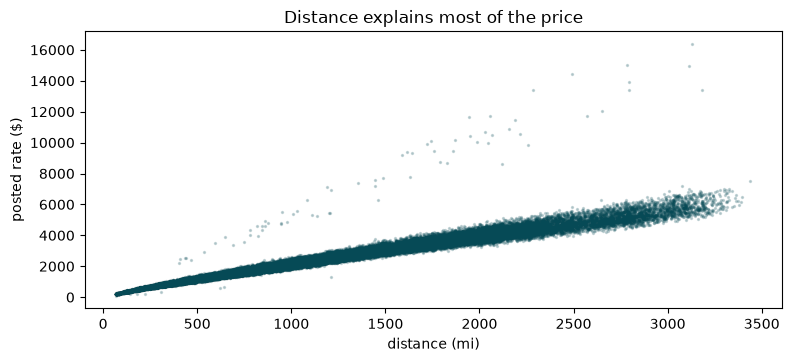

In [9]:
clean_rows = train[~outlier]
print("correlation with posted_rate:")
print(clean_rows[["distance", "weight", "market_index", "quote_signal", "posted_rate"]]
      .corr()["posted_rate"].round(3).to_string())

fig, ax = plt.subplots()
ax.scatter(clean_rows.distance, clean_rows.posted_rate, s=2, alpha=0.2, color="#064A56")
ax.set(title="Distance explains most of the price", xlabel="distance (mi)", ylabel="posted rate ($)")
plt.show()

Distance dominates: correlation 0.98 once the price outliers are removed (0.91 on the raw data). That is why the model predicts **rate per mile**
(log-scaled) and multiplies by distance afterwards: price per mile is a steadier target than
total price.

In [10]:
clean_rpm = clean_rows.posted_rate / clean_rows.distance
print(clean_rpm.groupby(clean_rows.equipment).median().round(2).to_string())

equipment
Dry Van    2.05
Flatbed    2.22
Reefer     2.31


Equipment shifts the price per mile: Dry Van is cheapest, then Flatbed, then Reefer
(refrigeration costs more). It goes into the model as a categorical feature.

         median_rpm  market_index  loads
date                                    
2025-01       2.029         0.927   4846
2025-02       2.062         0.996   4287
2025-03       2.140         1.073   4971
2025-04       2.147         1.207   4757
2025-05       2.191         1.301   4853
2025-06       2.248         1.280   4734
2025-07       2.188         1.201   4855
2025-08       2.121         0.981   4701
2025-09       2.160         0.893   4615
2025-10       2.165         0.957   4782


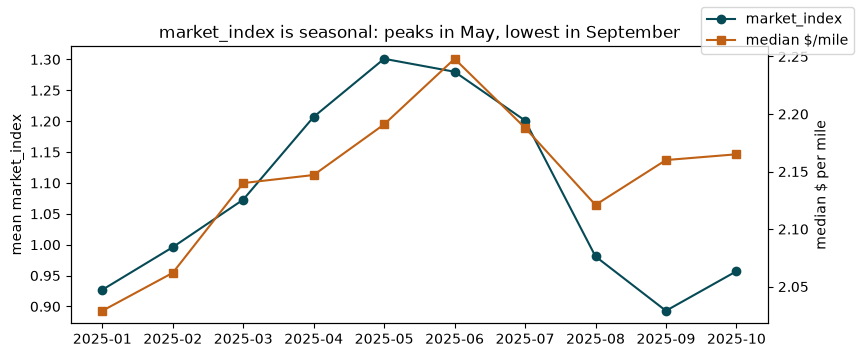

In [11]:
monthly = clean_rows.groupby(clean_rows.date.dt.to_period("M")).agg(
    median_rpm=("posted_rate", lambda s: (s / clean_rows.loc[s.index, "distance"]).median()),
    market_index=("market_index", "mean"),
    loads=("load_id", "size"),
).round(3)
print(monthly.to_string())

fig, ax1 = plt.subplots()
ax1.plot(monthly.index.astype(str), monthly.market_index, marker="o", color="#064A56", label="market_index")
ax1.set_ylabel("mean market_index")
ax2 = ax1.twinx()
ax2.plot(monthly.index.astype(str), monthly.median_rpm, marker="s", color="#C06014", label="median $/mile")
ax2.set_ylabel("median $ per mile")
ax1.set_title("market_index is seasonal: peaks in May, lowest in September")
fig.legend(loc="upper right")
plt.show()

`market_index` rises from about 0.93 in January to about 1.30 in May, then falls back to
about 0.89 in September. It acts as the seasonal signal. Price per mile follows it through the spring, but stays higher in September–October than the index alone suggests, so the index is not the only time effect. The main holdout (train Jan–Aug, test Sep–Oct) covers exactly this period, so its score shows whether the model copes when the index and price disagree. November–December have a similar index (about 0.92), so Sep–Oct is also the closest match to the months we predict. That is why `train.py` leaves out the
month: November and December never appear in training, and `market_index` carries the season instead.

The cleanest view of its effect is one fixed lane, which removes distance and location from the picture:

Lexington to Fort Wayne, Dry Van: 21 loads


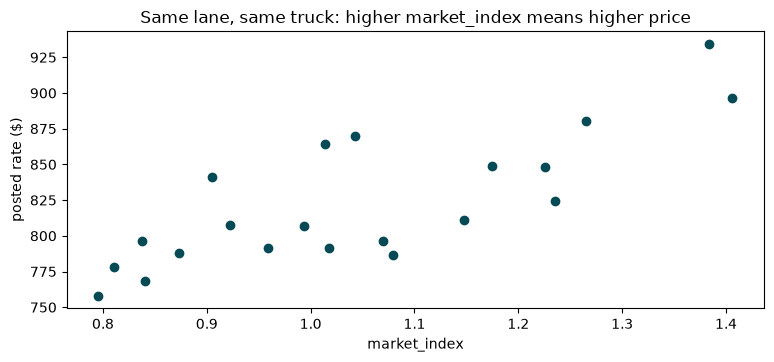

In [12]:
lane = clean_rows[(clean_rows.pickup == "Lexington") & (clean_rows.delivery == "Fort Wayne")
                  & (clean_rows.equipment == "Dry Van")]
print(f"Lexington to Fort Wayne, Dry Van: {len(lane)} loads")

fig, ax = plt.subplots()
ax.scatter(lane.market_index, lane.posted_rate, color="#064A56")
ax.set(title="Same lane, same truck: higher market_index means higher price",
       xlabel="market_index", ylabel="posted rate ($)")
plt.show()

In [13]:
dow = clean_rpm.groupby(clean_rows.date.dt.day_name()).median()
print(dow.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).round(3).to_string())

date
Monday       2.127
Tuesday      2.139
Wednesday    2.162
Thursday     2.172
Friday       2.159
Saturday     2.132
Sunday       2.128


Day of week has a small effect (midweek is slightly pricier), so it is kept as a minor feature.

## 4. December chart inputs

In [14]:
print("December file columns:", list(dec.columns))
print("Missing vs training features:",
      sorted(set(train.columns) - set(dec.columns) - {"load_id", "posted_rate"}))
val_dec = val[val.date.dt.month == 12]
print(f"\nvalidation.csv has {len(val_dec):,} December loads with real market_index / quote_signal")
val_dec.groupby(val_dec.date.dt.date)[["market_index", "quote_signal"]].mean().head()

December file columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
Missing vs training features: ['delivery_lat', 'delivery_lon', 'market_index', 'pickup_lat', 'pickup_lon', 'quote_signal']

validation.csv has 6,164 December loads with real market_index / quote_signal


,market_index,quote_signal
date,,
2025-12-01,0.834919,2.052023
2025-12-02,0.914680,2.034115
2025-12-03,0.994063,2.053293
2025-12-04,1.024021,2.065683
2025-12-05,0.975120,2.047368


The December file has no coordinates, `market_index` or `quote_signal`.
**Decision:** take the coordinates from the Lexington and Fort Wayne training rows (each city
has fixed coordinates), and use each day's average `market_index` and `quote_signal` from
validation.csv's December rows.

## 5. Summary of decisions

| Finding | Decision | Where in `train.py` |
|---|---|---|
| Forecasting task (train Jan–Oct, predict Nov–Dec) | time-based validation only, no random split | `main()` |
| Negative weights (sign flips) | `abs()` | `clean()` |
| Missing `weight` / `market_index` (<1%) | left as NaN, the model handles them | `make_model()` |
| Rate per mile below $1 or above $6 | dropped from training only | `clean()`, `RPM_LO` / `RPM_HI` |
| Trips at the 70-mile floor | kept as given, `detour_ratio` feature | `clean()`, `features()` |
| 8 cities never seen in training | coordinates instead of city names, unseen-city check | `features()`, `main()` |
| Distance dominates price | target is log rate per mile | `fit_target()` |
| `market_index` carries the season | no month feature | `features()` |
| December file missing inputs | fill from training coordinates and validation daily means | `fill_december()` |